In [12]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings

warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
df = pd.read_csv('Mall_Customers.csv')
print(df.head())
print(df.dtypes)
print(df.shape)
print(df.isnull().sum())

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object
(200, 5)
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


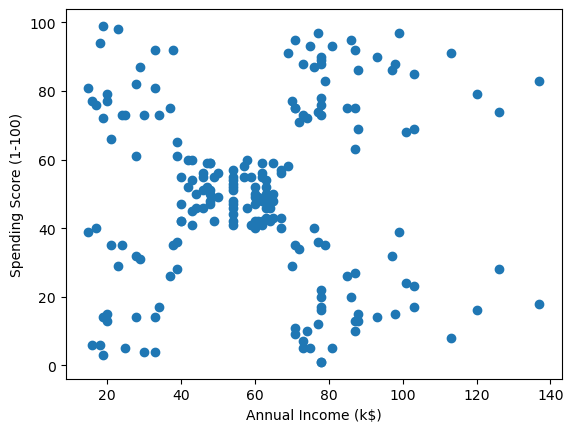

In [3]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

plt.scatter(X.iloc[:, 0], X.iloc[:, 1])
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

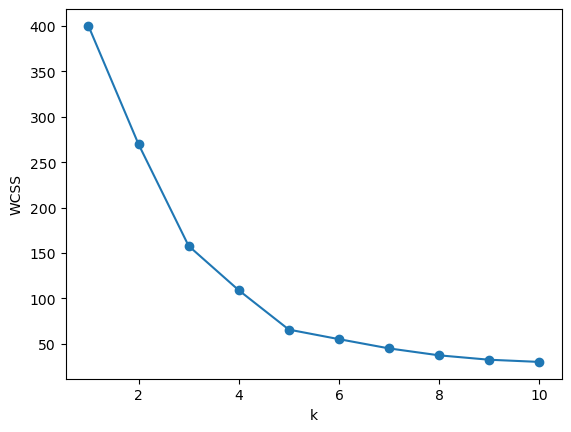

In [13]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('k')
plt.ylabel('WCSS')
plt.show()

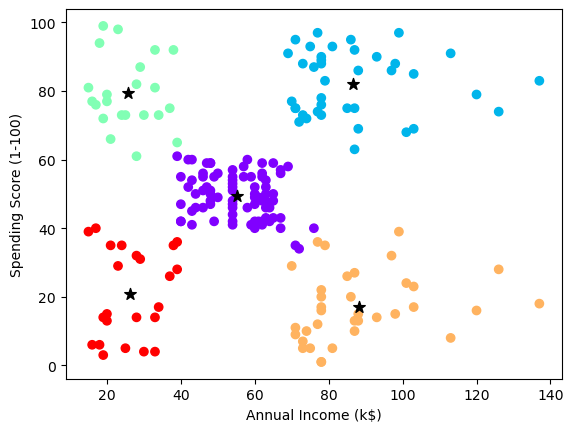

In [14]:
kmeans = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], c=df['Cluster'], cmap='rainbow')
# Unscale centroids for original scale plotting
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centroids[:, 0], centroids[:, 1], s=75, c='black', marker='*')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.show()

In [7]:
summary = df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean'
}).rename(columns={'CustomerID': 'Count'})
print(summary)

         Count  Annual Income (k$)  Spending Score (1-100)
Cluster                                                   
0           81           55.296296               49.518519
1           39           86.538462               82.128205
2           22           25.727273               79.363636
3           35           88.200000               17.114286
4           23           26.304348               20.913043
